# Import Libraries

In [1]:
import os
import math
import random
import shutil
import itertools
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import pwlf
from multiprocessing import Pool, cpu_count
from tqdm import tqdm, trange

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import brevitas.nn as qnn
from brevitas.nn import QuantLinear, QuantReLU, QuantConv2d
from brevitas.inject.enum import QuantType
from brevitas.quant_tensor.int_quant_tensor import IntQuantTensor
from brevitas.function.ops_ste import round_ste
from brevitas.quant import Int8WeightPerChannelFloat

from GRAUApproxToolkit import GRAU_Linear, GRAU_Conv2D, extend_min_max_ranges

# Network Definition

#### Neuron number and precision in each layer listed in this area for the VGG16 used in CIFAR10 classification

In [2]:
# -------- Block 0 --------
kernel_num_CONV_layer_0_0 = 64
kernel_num_CONV_layer_0_1 = 64

# -------- Block 1 --------
kernel_num_CONV_layer_1_0 = 128
kernel_num_CONV_layer_1_1 = 128

# -------- Block 2 --------
kernel_num_CONV_layer_2_0 = 256
kernel_num_CONV_layer_2_1 = 256
kernel_num_CONV_layer_2_2 = 256

# -------- Block 3 --------
kernel_num_CONV_layer_3_0 = 512
kernel_num_CONV_layer_3_1 = 512
kernel_num_CONV_layer_3_2 = 512

# -------- Block 4 --------
kernel_num_CONV_layer_4_0 = 512
kernel_num_CONV_layer_4_1 = 512
kernel_num_CONV_layer_4_2 = 512

neuron_num_FC_layer_0 = 1024
neuron_num_FC_layer_1 = 1024
neuron_num_OUT_layer  = 10

precision_CONV_layer_0_0 = 8
precision_CONV_layer_0_1 = 8

precision_CONV_layer_1_0 = 8
precision_CONV_layer_1_1 = 8

precision_CONV_layer_2_0 = 8
precision_CONV_layer_2_1 = 8
precision_CONV_layer_2_2 = 8

precision_CONV_layer_3_0 = 8
precision_CONV_layer_3_1 = 8
precision_CONV_layer_3_2 = 8

precision_CONV_layer_4_0 = 8
precision_CONV_layer_4_1 = 8
precision_CONV_layer_4_2 = 8

precision_FC_layer_0  = 8
precision_FC_layer_1  = 8
precision_OUT_layer   = 8

#### Hyperparameters setting here.

In [3]:
epochs = 200
batch_sizes = [256]
dropout_rates = [0.0]
lr_max_pool = [0.0002, 0.0001, 0.00005]
lr_min_pool = [0.0000001]

In [4]:
fit_segment_num=6
fit_points_num=1000

#### GPU selection. After decided which GPU to train, don't change it before completing the training

In [5]:
GPU_device = "cuda:1"

#### Training date output folder path, for different network model setting, please change the name of save_path

In [6]:
    save_path     = "VGG16_Sigmoid_8bit"

project_root  = os.path.abspath(".")
dataset_root  = os.path.join(project_root, "dataset")
train_root    = os.path.join(project_root, "train")
output_root   = os.path.join(train_root, save_path)
report_root  = os.path.join(project_root, "report")

print("Dataset Download Path: ", dataset_root, "\n")
print("Training Data Output Path: ", output_root, "\n")
print("Training Report Output Path: ", report_root)

os.makedirs(dataset_root, exist_ok=True)
os.makedirs(output_root, exist_ok=True)
os.makedirs(report_root, exist_ok=True)

Dataset Download Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/dataset 

Training Data Output Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/train/VGG16_Sigmoid_8bit 

Training Report Output Path:  /home/yuhao/project/GRAU-Approx-Toolkit/experiment/report


#### Following are the code to complete the network definition

In [7]:
kernel_size      = (3,3) 

In [8]:
in_channel_0_0   = 3
out_channel_0_0  = kernel_num_CONV_layer_0_0 
in_channel_0_1   = kernel_num_CONV_layer_0_0
out_channel_0_1  = kernel_num_CONV_layer_0_1 

in_channel_1_0   = kernel_num_CONV_layer_0_1
out_channel_1_0  = kernel_num_CONV_layer_1_0
in_channel_1_1   = kernel_num_CONV_layer_1_0
out_channel_1_1  = kernel_num_CONV_layer_1_1 

in_channel_2_0   = kernel_num_CONV_layer_1_1
out_channel_2_0  = kernel_num_CONV_layer_2_0
in_channel_2_1   = kernel_num_CONV_layer_2_0
out_channel_2_1  = kernel_num_CONV_layer_2_1 
in_channel_2_2   = kernel_num_CONV_layer_2_1
out_channel_2_2  = kernel_num_CONV_layer_2_2

in_channel_3_0   = kernel_num_CONV_layer_2_2
out_channel_3_0  = kernel_num_CONV_layer_3_0
in_channel_3_1   = kernel_num_CONV_layer_3_0
out_channel_3_1  = kernel_num_CONV_layer_3_1
in_channel_3_2   = kernel_num_CONV_layer_3_1
out_channel_3_2  = kernel_num_CONV_layer_3_2

in_channel_4_0   = kernel_num_CONV_layer_3_2
out_channel_4_0  = kernel_num_CONV_layer_4_0
in_channel_4_1   = kernel_num_CONV_layer_4_0
out_channel_4_1  = kernel_num_CONV_layer_4_1
in_channel_4_2   = kernel_num_CONV_layer_4_1
out_channel_4_2  = kernel_num_CONV_layer_4_2

# VGG16 on CIFAR10: 32 -> 16 -> 8 -> 4 -> 2 after 4 pools
input_length     = 2*2*kernel_num_CONV_layer_4_2

hidden_0         = neuron_num_FC_layer_0  
hidden_1         = neuron_num_FC_layer_1

output_length    = neuron_num_OUT_layer 

In [9]:
conv_0_0_bit_width = precision_CONV_layer_0_0
conv_0_1_bit_width = precision_CONV_layer_0_1

conv_1_0_bit_width = precision_CONV_layer_1_0
conv_1_1_bit_width = precision_CONV_layer_1_1

conv_2_0_bit_width = precision_CONV_layer_2_0
conv_2_1_bit_width = precision_CONV_layer_2_1
conv_2_2_bit_width = precision_CONV_layer_2_2

conv_3_0_bit_width = precision_CONV_layer_3_0
conv_3_1_bit_width = precision_CONV_layer_3_1
conv_3_2_bit_width = precision_CONV_layer_3_2

conv_4_0_bit_width = precision_CONV_layer_4_0
conv_4_1_bit_width = precision_CONV_layer_4_1
conv_4_2_bit_width = precision_CONV_layer_4_2

fc_0_bit_width = precision_FC_layer_0
fc_1_bit_width = precision_FC_layer_1
out_bit_width  = precision_OUT_layer

In [10]:
class VGG16(nn.Module):
    def __init__(self, dropout=0.5):
        super(VGG16, self).__init__()

        self.min_max_stats = defaultdict(list)
        
        self.input_quan = qnn.QuantIdentity(
                                quant_type='int',    
                                scaling_impl_type='stats', 
                                bit_width=conv_0_0_bit_width, 
                                return_quant_tensor=True)
        
        # ---------------- Block 0 (2 conv) ----------------
        self.conv0_0 = qnn.QuantConv2d(
                         in_channels=in_channel_0_0,
                         out_channels=out_channel_0_0,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_0_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn0_0   = nn.BatchNorm2d(out_channel_0_0)
        self.act0_0  = qnn.QuantSigmoid(
                         bit_width=conv_0_1_bit_width, 
                         return_quant_tensor=True)
        self.drop0_0 = nn.Dropout2d(dropout)
        
        self.conv0_1 = qnn.QuantConv2d( 
                         in_channels=in_channel_0_1,
                         out_channels=out_channel_0_1,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_0_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn0_1   = nn.BatchNorm2d(out_channel_0_1)
        self.act0_1  = qnn.QuantSigmoid(
                         bit_width=conv_1_0_bit_width, 
                         return_quant_tensor=True)
        self.drop0_1 = nn.Dropout2d(dropout)
        
        self.pool0 = nn.MaxPool2d(2)

        # ---------------- Block 1 (2 conv) ----------------
        self.conv1_0 = qnn.QuantConv2d( 
                         in_channels=in_channel_1_0,
                         out_channels=out_channel_1_0,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_1_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn1_0   = nn.BatchNorm2d(out_channel_1_0)
        self.act1_0  = qnn.QuantSigmoid(
                         bit_width=conv_1_1_bit_width, 
                         return_quant_tensor=True)
        self.drop1_0 = nn.Dropout2d(dropout)
        
        self.conv1_1 = qnn.QuantConv2d( 
                         in_channels=in_channel_1_1,
                         out_channels=out_channel_1_1,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_1_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn1_1   = nn.BatchNorm2d(out_channel_1_1)
        self.act1_1  = qnn.QuantSigmoid(
                         bit_width=conv_2_0_bit_width, 
                         return_quant_tensor=True)
        self.drop1_1 = nn.Dropout2d(dropout)
        
        self.pool1 = nn.MaxPool2d(2)

        # ---------------- Block 2 (3 conv) ----------------
        self.conv2_0 = qnn.QuantConv2d( 
                         in_channels=in_channel_2_0,
                         out_channels=out_channel_2_0,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_2_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn2_0   = nn.BatchNorm2d(out_channel_2_0)
        self.act2_0  = qnn.QuantSigmoid(
                         bit_width=conv_2_1_bit_width, 
                         return_quant_tensor=True)
        self.drop2_0 = nn.Dropout2d(dropout)
        
        self.conv2_1 = qnn.QuantConv2d( 
                         in_channels=in_channel_2_1,
                         out_channels=out_channel_2_1,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_2_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn2_1   = nn.BatchNorm2d(out_channel_2_1)
        self.act2_1  = qnn.QuantSigmoid(
                         bit_width=conv_2_2_bit_width, 
                         return_quant_tensor=True)
        self.drop2_1 = nn.Dropout2d(dropout)

        self.conv2_2 = qnn.QuantConv2d( 
                         in_channels=in_channel_2_2,
                         out_channels=out_channel_2_2,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_2_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn2_2   = nn.BatchNorm2d(out_channel_2_2)
        self.act2_2  = qnn.QuantSigmoid(
                         bit_width=conv_3_0_bit_width, 
                         return_quant_tensor=True)
        self.drop2_2 = nn.Dropout2d(dropout)
        
        self.pool2 = nn.MaxPool2d(2)

        # ---------------- Block 3 (3 conv) ----------------
        self.conv3_0 = qnn.QuantConv2d( 
                         in_channels=in_channel_3_0,
                         out_channels=out_channel_3_0,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_3_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn3_0   = nn.BatchNorm2d(out_channel_3_0)
        self.act3_0  = qnn.QuantSigmoid(
                         bit_width=conv_3_1_bit_width, 
                         return_quant_tensor=True)
        self.drop3_0 = nn.Dropout2d(dropout)

        self.conv3_1 = qnn.QuantConv2d( 
                         in_channels=in_channel_3_1,
                         out_channels=out_channel_3_1,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_3_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn3_1   = nn.BatchNorm2d(out_channel_3_1)
        self.act3_1  = qnn.QuantSigmoid(
                         bit_width=conv_3_2_bit_width, 
                         return_quant_tensor=True)
        self.drop3_1 = nn.Dropout2d(dropout)

        self.conv3_2 = qnn.QuantConv2d( 
                         in_channels=in_channel_3_2,
                         out_channels=out_channel_3_2,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_3_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn3_2   = nn.BatchNorm2d(out_channel_3_2)
        self.act3_2  = qnn.QuantSigmoid(
                         bit_width=conv_4_0_bit_width, 
                         return_quant_tensor=True)
        self.drop3_2 = nn.Dropout2d(dropout)

        self.pool3 = nn.MaxPool2d(2)

        # ---------------- Block 4 (3 conv) ----------------
        self.conv4_0 = qnn.QuantConv2d( 
                         in_channels=in_channel_4_0,
                         out_channels=out_channel_4_0,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_4_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn4_0   = nn.BatchNorm2d(out_channel_4_0)
        self.act4_0  = qnn.QuantSigmoid(
                         bit_width=conv_4_1_bit_width, 
                         return_quant_tensor=True)
        self.drop4_0 = nn.Dropout2d(dropout)

        self.conv4_1 = qnn.QuantConv2d( 
                         in_channels=in_channel_4_1,
                         out_channels=out_channel_4_1,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_4_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn4_1   = nn.BatchNorm2d(out_channel_4_1)
        self.act4_1  = qnn.QuantSigmoid(
                         bit_width=conv_4_2_bit_width, 
                         return_quant_tensor=True)
        self.drop4_1 = nn.Dropout2d(dropout)

        self.conv4_2 = qnn.QuantConv2d( 
                         in_channels=in_channel_4_2,
                         out_channels=out_channel_4_2,
                         kernel_size=kernel_size, 
                         stride=1, 
                         padding=1,
                         weight_bit_width=conv_4_2_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         bias=False,
                         return_quant_tensor=True)
        self.bn4_2   = nn.BatchNorm2d(out_channel_4_2)
        self.act4_2  = qnn.QuantSigmoid(
                         bit_width=fc_0_bit_width, 
                         return_quant_tensor=True)
        self.drop4_2 = nn.Dropout2d(dropout)

        # ---------------- FC (keep your original style) ----------------
        self.fc3 = qnn.QuantLinear(
                         in_features=input_length,
                         out_features=hidden_0,
                         bias=False,
                         weight_bit_width=fc_0_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         return_quant_tensor=True)
        self.bn3   = nn.BatchNorm1d(hidden_0)
        self.act3  = qnn.QuantSigmoid(
                         bit_width=fc_1_bit_width, 
                         return_quant_tensor=True)
        self.drop3 = nn.Dropout(dropout)

        self.fc4 = qnn.QuantLinear(
                         in_features=hidden_0,
                         out_features=hidden_1,
                         bias=False,
                         weight_bit_width=fc_1_bit_width,
                         weight_quant=Int8WeightPerChannelFloat,
                         return_quant_tensor=True)
        self.bn4   = nn.BatchNorm1d(hidden_1)
        self.act4  = qnn.QuantSigmoid(
                         bit_width=out_bit_width, 
                         return_quant_tensor=True)
        self.drop4 = nn.Dropout(dropout)

        self.out_quan = qnn.QuantLinear(
                         in_features=hidden_1,
                         out_features=output_length,
                         bias=False,
                         weight_bit_width=out_bit_width,
                         weight_quant=Int8WeightPerChannelFloat)

    def forward(self, x):

        out = self.input_quan(x)
        
        out = self.conv0_0(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv0_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop0_0(self.act0_0(self.bn0_0(out_int)))
        
        out = self.conv0_1(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv0_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop0_1(self.act0_1(self.bn0_1(out_int)))
        
        out = self.pool0(out)
        
        out = self.conv1_0(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv1_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop1_0(self.act1_0(self.bn1_0(out_int)))
        
        out = self.conv1_1(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv1_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop1_1(self.act1_1(self.bn1_1(out_int)))
        
        out = self.pool1(out)
        
        out = self.conv2_0(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv2_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop2_0(self.act2_0(self.bn2_0(out_int)))
        
        out = self.conv2_1(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv2_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop2_1(self.act2_1(self.bn2_1(out_int)))
        
        out = self.conv2_2(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv2_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop2_2(self.act2_2(self.bn2_2(out_int)))
        
        out = self.pool2(out)
        
        out = self.conv3_0(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv3_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop3_0(self.act3_0(self.bn3_0(out_int)))
        
        out = self.conv3_1(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv3_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop3_1(self.act3_1(self.bn3_1(out_int)))
        
        out = self.conv3_2(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv3_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop3_2(self.act3_2(self.bn3_2(out_int)))
        
        out = self.pool3(out)
        
        out = self.conv4_0(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv4_0'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop4_0(self.act4_0(self.bn4_0(out_int)))
        
        out = self.conv4_1(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv4_1'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop4_1(self.act4_1(self.bn4_1(out_int)))
        
        out = self.conv4_2(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['conv4_2'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop4_2(self.act4_2(self.bn4_2(out_int)))

        out = out.reshape(out.shape[0], -1)
        
        out = self.fc3(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['fc3'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop3(self.act3(self.bn3(out_int)))
        
        out = self.fc4(out)
        out_int = round_ste(out._pre_round_int_value).type(torch.float32)
        self.min_max_stats['fc4'].append((out_int.min().item(), out_int.max().item()))
        out = self.drop4(self.act4(self.bn4(out_int)))

        out = self.out_quan(out)
        
        return out

In [11]:
class PWLF_VGG16(nn.Module):
    def __init__(self, original_model, extended_min_max_stats, device, dropout=0.5, fit_segment_num=6, fit_points_num=1000, pot_min_exp=-10, pot_max_exp=6):
        super(PWLF_VGG16, self).__init__()
        
        self.input_quan = original_model.input_quan
        
        # ---------------- Block 0 (2 conv) ----------------
        
        self.conv0_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv0_0,
                                        bn_layer=original_model.bn0_0,
                                        act_layer=original_model.act0_0,
                                        min_max_stats=extended_min_max_stats['conv0_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv0_1    = GRAU_Conv2D(
                                        conv_layer=original_model.conv0_1,
                                        bn_layer=original_model.bn0_1,
                                        act_layer=original_model.act0_1,
                                        min_max_stats=extended_min_max_stats['conv0_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.pool0 = nn.MaxPool2d(2)

        # ---------------- Block 1 (2 conv) ----------------
        
        self.conv1_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv1_0,
                                        bn_layer=original_model.bn1_0,
                                        act_layer=original_model.act1_0,
                                        min_max_stats=extended_min_max_stats['conv1_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv1_1    = GRAU_Conv2D(
                                        conv_layer=original_model.conv1_1,
                                        bn_layer=original_model.bn1_1,
                                        act_layer=original_model.act1_1,
                                        min_max_stats=extended_min_max_stats['conv1_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.pool1 = nn.MaxPool2d(2)

        # ---------------- Block 2 (3 conv) ----------------
        
        self.conv2_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv2_0,
                                        bn_layer=original_model.bn2_0,
                                        act_layer=original_model.act2_0,
                                        min_max_stats=extended_min_max_stats['conv2_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv2_1    = GRAU_Conv2D(
                                        conv_layer=original_model.conv2_1,
                                        bn_layer=original_model.bn2_1,
                                        act_layer=original_model.act2_1,
                                        min_max_stats=extended_min_max_stats['conv2_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv2_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv2_2,
                                        bn_layer=original_model.bn2_2,
                                        act_layer=original_model.act2_2,
                                        min_max_stats=extended_min_max_stats['conv2_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.pool2 = nn.MaxPool2d(2)

        # ---------------- Block 3 (3 conv) ----------------
        
        self.conv3_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv3_0,
                                        bn_layer=original_model.bn3_0,
                                        act_layer=original_model.act3_0,
                                        min_max_stats=extended_min_max_stats['conv3_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv3_1    = GRAU_Conv2D(
                                        conv_layer=original_model.conv3_1,
                                        bn_layer=original_model.bn3_1,
                                        act_layer=original_model.act3_1,
                                        min_max_stats=extended_min_max_stats['conv3_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv3_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv3_2,
                                        bn_layer=original_model.bn3_2,
                                        act_layer=original_model.act3_2,
                                        min_max_stats=extended_min_max_stats['conv3_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )

        self.pool3 = nn.MaxPool2d(2)

        # ---------------- Block 4 (3 conv) ----------------
        
        self.conv4_0    = GRAU_Conv2D(
                                        conv_layer=original_model.conv4_0,
                                        bn_layer=original_model.bn4_0,
                                        act_layer=original_model.act4_0,
                                        min_max_stats=extended_min_max_stats['conv4_0'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv4_1    = GRAU_Conv2D(
                                        conv_layer=original_model.conv4_1,
                                        bn_layer=original_model.bn4_1,
                                        act_layer=original_model.act4_1,
                                        min_max_stats=extended_min_max_stats['conv4_1'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )
        
        self.conv4_2    = GRAU_Conv2D(
                                        conv_layer=original_model.conv4_2,
                                        bn_layer=original_model.bn4_2,
                                        act_layer=original_model.act4_2,
                                        min_max_stats=extended_min_max_stats['conv4_2'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                     )

        # ---------------- FC (keep your original style) ----------------
        
        self.fc3       = GRAU_Linear(
                                        linear_layer=original_model.fc3,
                                        bn_layer=original_model.bn3,
                                        act_layer=original_model.act3,
                                        min_max_stats=extended_min_max_stats['fc3'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                    )
        
        self.fc4       = GRAU_Linear(
                                        linear_layer=original_model.fc4,
                                        bn_layer=original_model.bn4,
                                        act_layer=original_model.act4,
                                        min_max_stats=extended_min_max_stats['fc4'],
                                        device=device,
                                        segment_num=fit_segment_num,       
                                        n_fit_points=fit_points_num,
                                        min_gap=1,
                                        pot_min_exp=pot_min_exp,
                                        pot_max_exp=pot_max_exp,
                                    )
        
        self.out_quan   = original_model.out_quan

    def forward(self, x, mode="PWLF"):
        

        out = self.input_quan(x)
        
        out = self.conv0_0(out, mode)
        out = self.conv0_1(out, mode)
        out = self.pool0(out)
        
        out = self.conv1_0(out, mode)
        out = self.conv1_1(out, mode)
        out = self.pool1(out)
        
        out = self.conv2_0(out, mode)
        out = self.conv2_1(out, mode)
        out = self.conv2_2(out, mode)
        out = self.pool2(out)
        
        out = self.conv3_0(out, mode)
        out = self.conv3_1(out, mode)
        out = self.conv3_2(out, mode)
        out = self.pool3(out)
        
        out = self.conv4_0(out, mode)
        out = self.conv4_1(out, mode)
        out = self.conv4_2(out, mode)
        
        out = out.reshape(out.shape[0], -1)

        out = self.fc3(out, mode)
        out = self.fc4(out, mode)
        
        out = self.out_quan(out)
        
        return out

# Random Seed Utility

In [12]:
def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Define Dataloader

In [13]:
test_batch_size = 4096

In [14]:
def get_dataloaders(batch_size):    
    CIFAR100_MEAN = (0.5071, 0.4867, 0.4408)
    CIFAR100_STD  = (0.2675, 0.2565, 0.2761)

    train_dataset = datasets.CIFAR10(   dataset_root, 
                                        train=True, 
                                        download=True, 
                                        transform = transforms.Compose([
                                            transforms.RandomCrop(32, padding=4),
                                            transforms.RandomHorizontalFlip(),
                                            transforms.ToTensor(),
                                            transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD)
                                        ])
                                    )
    test_dataset  = datasets.CIFAR10(   dataset_root, 
                                        train=False, 
                                        download=True, 
                                        transform = transforms.Compose([
                                            transforms.ToTensor(),
                                            transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD)
                                        ])
                                    )
    val_size = int(0.2 * len(train_dataset))
    train_size = len(train_dataset) - val_size
    train_set, val_set = random_split(train_dataset, [train_size, val_size])
    return (
        DataLoader(
            train_set,
            batch_size=batch_size,
            shuffle=True,
            num_workers=6,
            pin_memory=True,
            persistent_workers=True,
            prefetch_factor=4,
        ),
        DataLoader(
            val_set,
            batch_size=batch_size,
            shuffle=False,
            num_workers=6,
            pin_memory=True,
            persistent_workers=True,
            prefetch_factor=4,
        ),
        DataLoader(test_dataset, batch_size=test_batch_size),
    )

# Evaluation Pipeline

In [15]:
def evaluate(model, criterion, device, loader, train):
    model.eval()
    loss_total, correct, total = 0, 0, 0
    with torch.no_grad():
        if (train):
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                loss_total += loss.item() * x.size(0)
                _, pred = out.max(1)
                correct += (pred == y).sum().item()
                total += x.size(0)
        else:
            for x, y in tqdm(loader, desc="Evaluation", leave=True):
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                loss_total += loss.item() * x.size(0)
                _, pred = out.max(1)
                correct += (pred == y).sum().item()
                total += x.size(0)
    return loss_total / total, correct / total

In [16]:
def pwlf_evaluate(model, criterion, device, loader, mode="PWLF"):
    model.eval()
    loss_total, correct, total = 0, 0, 0
    with torch.no_grad():
        for x, y in tqdm(loader, desc="Evaluation", leave=True):
            x, y = x.to(device), y.to(device)
            out = model(x, mode)
            loss = criterion(out, y)
            loss_total += loss.item() * x.size(0)
            _, pred = out.max(1)
            correct += (pred == y).sum().item()
            total += x.size(0)
    return loss_total / total, correct / total

# Plot Training Loss and Accuracy

In [17]:
def plot_train(history, save_dir):
    # Plot and show
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.legend()
    plt.title("Loss")

    plt.subplot(1, 2, 2)
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.legend()
    plt.title("Accuracy")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, "training_plot.png"))
    plt.show()

# Training, Validation, and Testing Pipeline

In [18]:
def train_validate_test(config, save_dir, plot_enable=False):
    set_random_seed()
    os.makedirs(save_dir, exist_ok=True)
    log_file = os.path.join(save_dir, "training_log.txt")
    resume_path = os.path.join(save_dir, "checkpoint.pth")

    epochs, batch_size, lr_max, lr_min, dropout = config
    train_loader, val_loader, test_loader = get_dataloaders(batch_size)
    device = torch.device(GPU_device if torch.cuda.is_available() else "cpu")
    model = VGG16(dropout=dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr_max)

    start_epoch = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    if os.path.exists(resume_path):
        ckpt = torch.load(resume_path)
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        optimizer.load_state_dict(ckpt["optimizer_state"])
        history = ckpt["history"]
        start_epoch = ckpt["epoch"] + 1
        print(f"🔄 Resuming from epoch {start_epoch}")
    else:
        with open(log_file, "w") as f:
            f.write("Training started\n")

    # Training Loop
    t = trange(start_epoch, epochs, desc="Training", leave=True)
    for epoch in t:
        model.train()
        lr = lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * epoch / epochs))
        for g in optimizer.param_groups:
            g["lr"] = lr

        train_loss, correct, total = 0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
            _, pred = out.max(1)
            correct += (pred == y).sum().item()
            total += x.size(0)

        val_loss, val_acc = evaluate(model, criterion, device, val_loader, train=True)
        train_loss /= total
        train_acc = correct / total
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        log_line = (f"Epoch {epoch+1}/{epochs} - LR: {lr:.6f} | "
                    f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
                    f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")
        #print(log_line)
        with open(log_file, "a") as f:
            f.write(log_line + "\n")

        t.set_description("| LR: %.6f | Train Acc: %.4f | Val Acc: %.4f |" % (lr, train_acc, val_acc))
        t.refresh()

        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history
        }, resume_path)

    # Plot and show the training history
    if plot_enable:
        plot_train(history, save_dir)

    # Test the original trained model
    original_test_loss, original_test_acc = evaluate(model, criterion, device, test_loader, train=False)
    final_line = f"Original Model Final Test Loss: {original_test_loss:.4f} Accuracy: {original_test_acc:.4f}"
    print(final_line)
    with open(log_file, "a") as f:
        f.write("Training completed\n")
        f.write(final_line + "\n")

    # Save the trained model
    torch.save(model.state_dict(), os.path.join(save_dir, "final_model.pth"))
    with open(log_file, "a") as f:
        f.write(final_line + "\n")
    print("\n")

    return original_test_acc, resume_path

# Hyperparameter Searching for Network Training and Testing

In [19]:
def Hyperparameter_searching(epochs, batch_sizes, lr_max_pool, lr_min_pool, dropout_rates, plot_enable=False):
    
    epochs = epochs
    batch_sizes = batch_sizes
    lr_max_pool = lr_max_pool
    lr_min_pool = lr_min_pool
    
    all_runs = [
        f"batch{bs}_lr_max_{lr_max}_min_{lr_min}"
        for bs, lr_max, lr_min in itertools.product(batch_sizes, lr_max_pool, lr_min_pool)
    ]
    
    completed_runs = []
    for run in all_runs:
        log_path = os.path.join(output_root, run, "training_log.txt")
        if os.path.exists(log_path):
            with open(log_path, "r") as f:
                if any("Training completed" in line for line in f):
                    completed_runs.append(run)
    
    results = []
    for batch_size, lr_max, lr_min, dropout in itertools.product(batch_sizes, lr_max_pool, lr_min_pool, dropout_rates):
        run_name = f"batch{batch_size}_lr_max_{lr_max}_min_{lr_min}_dp{dropout}"
        save_dir = os.path.join(output_root, run_name)
    
        print(f"🚀 Running: {run_name}")
        acc, resume_path = train_validate_test([epochs, batch_size, lr_max, lr_min, dropout], save_dir, plot_enable)
        
        results.append((run_name, acc, epochs, batch_size, lr_max, lr_min, dropout, resume_path))
    
    results.sort(key=lambda x: x[1], reverse=True)
    best_config, best_acc, best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path = results[0]
    print(f"🏆 Best Config: {best_config} Accuracy: {best_acc:.4f}")
    
    with open(os.path.join(report_root, save_path+"_report.csv"), "w") as f:
        f.write("Epoch,Batch Size,LR_max,LR_min,Dropout,Accuracy\n")
        for name, acc, epoch, batch_size, lr_max, lr_min, dropout, resume_path in results:
            f.write(f"{epoch},{batch_size},{lr_max:.4f},{lr_min:.6f},{dropout:.4f},{acc:.4f}\n")

    return best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path

In [20]:
def best_evaluation(epochs, batch_size, lr_max, lr_min, dropout, resume_path):
    set_random_seed()

    epochs, batch_size, lr_max, lr_min, dropout = epochs, batch_size, lr_max, lr_min, dropout
    train_loader, val_loader, test_loader = get_dataloaders(batch_size)
    device = torch.device(GPU_device if torch.cuda.is_available() else "cpu")
    model = VGG16(dropout=dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr_max)

    if os.path.exists(resume_path):
        ckpt = torch.load(resume_path)
        model.load_state_dict(ckpt["model_state"])
        model.to(device)
        optimizer.load_state_dict(ckpt["optimizer_state"])
        history = ckpt["history"]
        print("Best model loaded.")
    else:
        print("Best model lost.")

    with open(os.path.join(report_root, save_path+"_pwlf.csv"), "w") as f:
        f.write("model,segment_num,exp_min,exp_max,accuracy\n")

    # Test the original trained model
    original_test_loss, original_test_acc = evaluate(model, criterion, device, test_loader, train=False)
    final_line = f"Best Original Model Final Test Loss: {original_test_loss:.4f} Accuracy: {original_test_acc:.4f}"
    print(final_line)
    print("\n")

    with open(os.path.join(report_root, save_path+"_pwlf.csv"), "a") as f:
        f.write(f"{'original'},{0},{0},{0},{original_test_acc:.4f}\n")

    extended_min_max_range = extend_min_max_ranges(model.min_max_stats)

    with open(os.path.join(report_root, save_path+"_input_range.csv"), "w") as f:
        f.write("layer,exp_min,exp_max\n")
        for name, min_max_stats in extended_min_max_range.items():
            exp_min, exp_max = min_max_stats
            f.write(f"{name},{exp_min:.1f},{exp_max:.1f}\n")

    fit_points_num=1000
    
    #################################
    
    fit_segment_num_list = [4, 6, 8, 10]
    exp_span_list = [16, 8, 4]
    
    #################################
    
    for fit_segment_num in fit_segment_num_list:
    
        print("Setting segment number of PWLF as ", fit_segment_num)

        pwlf_model = PWLF_VGG16(
            model,
            extended_min_max_range,
            device,
            dropout,
            fit_segment_num,
            fit_points_num,
            -32,
            -17
        ).to(device)

        # Test the PWLF model
        pwlf_test_loss, pwlf_test_acc = pwlf_evaluate(
            pwlf_model, criterion, device, test_loader, mode="PWLF"
        )
        final_line = f"PWLF Test Loss: {pwlf_test_loss:.4f} Accuracy: {pwlf_test_acc:.4f}"
        print(final_line)

        with open(os.path.join(report_root, save_path + "_pwlf.csv"), "a") as f:
            f.write(f"{'PWLF'},{fit_segment_num},{0},{0},{pwlf_test_acc:.4f}\n")
    
    #################################
    
    for fit_segment_num in fit_segment_num_list:
        for exp_span in exp_span_list:
            for pot_min_exp in range(-32, -exp_span + 1, 2):
                pot_max_exp = pot_min_exp + exp_span - 1
    
                print("Setting segment number of PWLF as ", fit_segment_num)
                print("Setting potential 2^n from 2^", pot_min_exp, " to 2^", pot_max_exp)
    
                pwlf_model = PWLF_VGG16(
                    model,
                    extended_min_max_range,
                    device,
                    dropout,
                    fit_segment_num,
                    fit_points_num,
                    pot_min_exp,
                    pot_max_exp
                ).to(device)
    
                # Test the PoT-PWLF model
                pot_pwlf_test_loss, pot_pwlf_test_acc = pwlf_evaluate(
                    pwlf_model, criterion, device, test_loader, mode="PoT-PWLF"
                )
                final_line = f"PoT-PWLF Test Loss: {pot_pwlf_test_loss:.4f} Accuracy: {pot_pwlf_test_acc:.4f}"
                print(final_line)
    
                # Test the APoT-PWLF model
                apot_pwlf_test_loss, apot_pwlf_test_acc= pwlf_evaluate(
                    pwlf_model, criterion, device, test_loader, mode="APoT-PWLF"
                )
                final_line = f"APoT-PWLF Test Loss: {apot_pwlf_test_loss:.4f} Accuracy: {apot_pwlf_test_acc:.4f}"
                print(final_line)
                print("\n")
    
                with open(os.path.join(report_root, save_path + "_pwlf.csv"), "a") as f:
                    f.write(f"{'PoT-PWLF'},{fit_segment_num},{pot_min_exp},{pot_max_exp},{pot_pwlf_test_acc:.4f}\n")
                    f.write(f"{'APoT-PWLF'},{fit_segment_num},{pot_min_exp},{pot_max_exp},{apot_pwlf_test_acc:.4f}\n")

    # pwlf_model.fc0.plot_all_act()
    # pwlf_model.fc0.print_activation_pwlf_params()

🚀 Running: batch256_lr_max_0.0002_min_1e-07_dp0.0


Files already downloaded and verified


Files already downloaded and verified


🔄 Resuming from epoch 200


Training: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

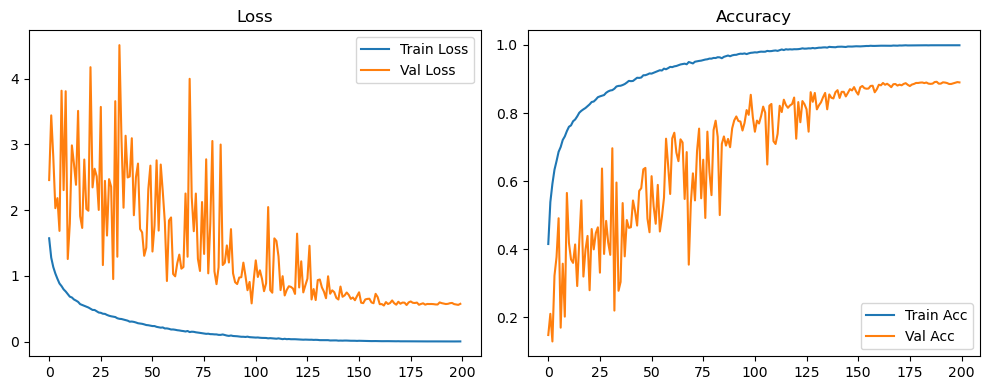

Evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/torch/_tensor.py:1362: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/c10/core/TensorImpl.h:1900.)
  return super().rename(names)


/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/torch/csrc/utils/python_arg_parser.cpp:368.)
  return F.conv2d(input, weight, bias, self.stride,


/home/yuhao/anaconda3/envs/brevitas/lib/python3.9/site-packages/brevitas/nn/quant_linear.py:69: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at /opt/conda/conda-bld/pytorch_1695392022560/work/torch/csrc/utils/python_arg_parser.cpp:368.)
  output_tensor = linear(x, quant_weight, quant_bias)
Evaluation:  33%|███▎      | 1/3 [00:02<00:04,  2.00s/it]

Evaluation:  67%|██████▋   | 2/3 [00:02<00:01,  1.34s/it]

...

Files already downloaded and verified


Files already downloaded and verified


🔄 Resuming from epoch 200


Training: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

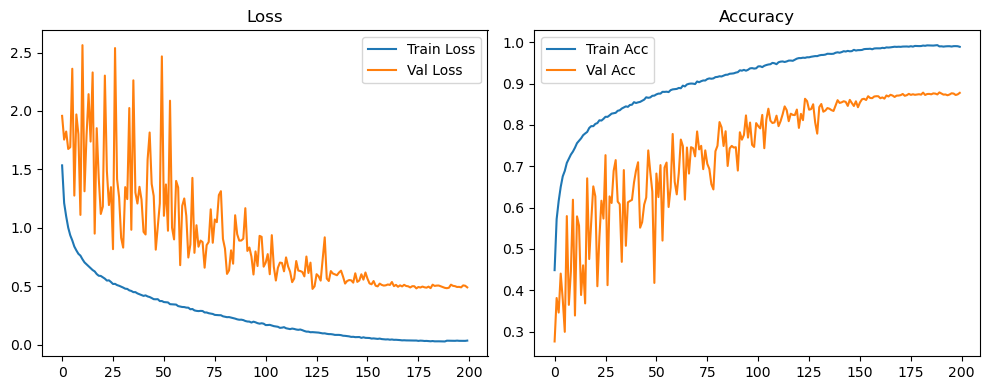

Evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluation:  33%|███▎      | 1/3 [00:00<00:01,  1.19it/s]

Evaluation:  67%|██████▋   | 2/3 [00:01<00:00,  1.18it/s]

Evaluation: 100%|██████████| 3/3 [00:02<00:00,  1.58it/s]

Evaluation: 100%|██████████| 3/3 [00:02<00:00,  1.45it/s]

...

Files already downloaded and verified


Files already downloaded and verified


🔄 Resuming from epoch 200


Training: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

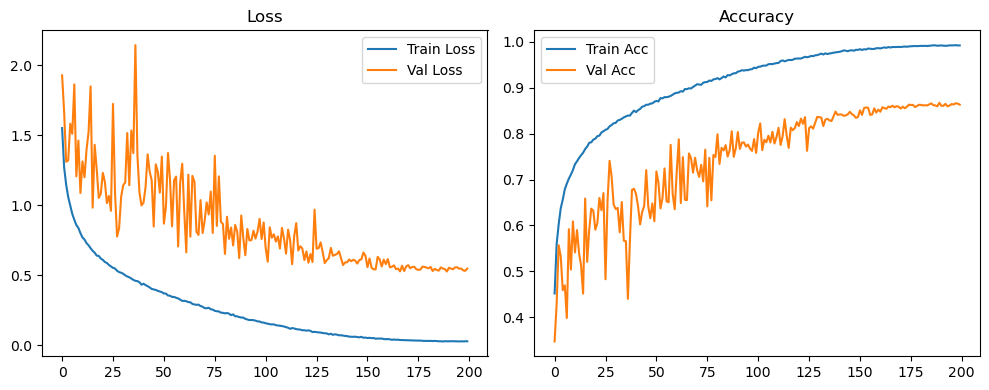

Evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluation:  33%|███▎      | 1/3 [00:00<00:01,  1.04it/s]

Evaluation:  67%|██████▋   | 2/3 [00:01<00:00,  1.12it/s]

Evaluation: 100%|██████████| 3/3 [00:02<00:00,  1.52it/s]

Evaluation: 100%|██████████| 3/3 [00:02<00:00,  1.37it/s]

Original Model Final Test Loss: 0.5416 Accuracy: 0.8678


🏆 Best Config: batch256_lr_max_0.0002_min_1e-07_dp0.0 Accuracy: 0.8871


In [21]:
best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path = Hyperparameter_searching(epochs, batch_sizes, lr_max_pool, lr_min_pool, dropout_rates, plot_enable=True)

In [22]:
best_evaluation(best_epochs, best_batch_size, best_lr_max, best_lr_min, best_dropout, best_resume_path)

Files already downloaded and verified


Files already downloaded and verified


Best model loaded.


Evaluation:   0%|          | 0/3 [00:00<?, ?it/s]

Evaluation:  33%|███▎      | 1/3 [00:00<00:01,  1.19it/s]

...

Evaluation:  33%|███▎      | 1/3 [00:01<00:02,  1.40s/it]

Evaluation:  67%|██████▋   | 2/3 [00:02<00:01,  1.40s/it]

Evaluation: 100%|██████████| 3/3 [00:03<00:00,  1.19s/it]

Evaluation: 100%|██████████| 3/3 [00:03<00:00,  1.25s/it]

APoT-PWLF Test Loss: 2360.8201 Accuracy: 0.1000


